## 1)LIBRARY AND ACCELERATOR CHOICE

---

Same as for the CNN of the MNIST, we will use:
  * the `torch.nn` module, which provides the layers (tensor operations packaged with their weights) and the loss function;
  * the class `DataLoader` to separate the dataset into batches.
  * the library `torchvision` because there are a lot of tools that will help to develop a picture-recognition AI.

After the choice of the accelerator used, we print it to be sure we are not using the CPU, which would slow down the training.

*Note: This notebook was run on Google Colab with a T4 GPU.*


In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(device)

cuda


## 2)DATA

---

We use the CIFAR-10 dataset that is already segmented in two parts, the data for training(50 000 pictures) and the data for testing(10 000 pictures). The pictures are colored unlike in the MNIST dataset and there is 10 categories of pictures. The objectives is for the model to predicted the right category for each picture.

Then we adapt the data with the object `transform` so we have pictures as tensors and to ensure the tensors are normalized (`Normalize`). For the trainning set, we also apply a random flip and a random crop because it allows us to artificially multiply the dataset, introducing greater diversity in the trainning dataset. Thus the model has a better accuracy on the test set.

After that we separate in batches, to be more efficient in time and have a more stable evolution of the weights.

At the end we verify that the data have the right shape: batches of 64 pictures of 32×32 pixels in RGB in the picture for each of the 64 pictures.


*Note: The mean of the MNIST training set and its standard deviation is find using the first 4 lines*


In [ ]:
ds = datasets.CIFAR10(root="data", train=True, download=True)
x = torch.tensor(ds.data, dtype=torch.float32) / 255   # (50000, 32, 32, 3)
Mean=x.mean(dim=(0,1,2))
Dev=x.std(dim=(0,1,2))
print(Mean, Dev)

100%|██████████| 170M/170M [50:01<00:00, 56.8kB/s]


tensor([0.4914, 0.4822, 0.4465]) tensor([0.2470, 0.2435, 0.2616])


In [ ]:
train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4), #the RandomCrop and HorizontalFlip are standards on CNN for the CIFAR-10 dataset
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(Mean, Dev),
])


test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(Mean, Dev),
])

train_data = datasets.CIFAR10(root="data", train=True,  download=True, transform=train_tf)
test_data  = datasets.CIFAR10(root="data", train=False, download=True, transform=test_tf)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_data,  batch_size=64)

x, y = next(iter(train_loader))
print(x.shape, y.shape)

torch.Size([64, 3, 32, 32]) torch.Size([64])


## 3)MODEL

---

This CNN is organized into 3 convolutional blocks (conv + batch norm + ReLU + max-pool), to extract features, followed by 2 fully connected layers, to classify according to the features recognized. In between, we introduce a `dropout` layer to avoid having some neurone which do all the work while some served no purpose which could cause overfitting.

With a first layer (`conv1`) that will allow the model to detect 32 patterns which would be recognised as the most important during the training on a 3 by 3 pixel zone for each pixel on the picture. We apply `ReLU` operation to introduce non-linearity in the model after every layer (except the last) and `pool` to reduce the number of pixel considered with every step by picking the best score for each square of 2 by 2 pixels. There is also a `BatchNorm` operation to normalize the data after each layer to diminish the number of trainning needed to approach an acceptable accuracy(because the batchnorm introduce a bias, we don't need the ones in the conv2d layer).

After that a second layer (`conv2`) will be used similarly to the first layer, except that we double the number of patterns recognisable.

Similarly, we have a third layer (`conv3`). The majority of the computation is done during this phase.

The last two layers take the whole picture into account. The first `fc1` is used after flattening the pictures in one line and evaluates 128 patterns. The second `fc2` is here because we introduce a `ReLU` in between these two layers to combine non-linearly the result of the previous layer. The output is the score for each digit.

In the last three lines,We download the model on the device then we verify that the output has the right shape: a tensor grouping the 10 scores for each of the 64 pictures. And we count the number of parameter.

In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1, bias=False)
        self.bn1   = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1, bias=False)
        self.bn3   = nn.BatchNorm2d(128)
        self.pool  = nn.MaxPool2d(2)
        self.relu  = nn.ReLU()
        self.drop  = nn.Dropout(0.3)
        self.fc1   = nn.Linear(128 * 4 * 4, 256)
        self.fc2   = nn.Linear(256, 10)
    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))   # 3×32×32   → 32×16×16
        x = self.pool(self.relu(self.bn2(self.conv2(x))))   # 32×16×16  → 64×8×8
        x = self.pool(self.relu(self.bn3(self.conv3(x))))   # 64×8×8    → 128×4×4
        x = torch.flatten(x, 1)                             # → 2048
        x = self.drop(x)
        x = self.relu(self.fc1(x))                          # → 256
        x = self.drop(x)
        return self.fc2(x)                                  # → 10 scores

model = CNN().to(device)
print(model(x.to(device)).shape)                            # torch.Size([64, 10])
print(sum(p.numel() for p in model.parameters()))           # 620586

torch.Size([64, 10])
620586


## 4)TRAINING

---

We have two functions, one to train the model with the whole training dataset (one epoch) and one to test it with the test dataset.

For the training, we use an improved version of the Gradient Descent, `Adam`. The `loss_fn` object turn the scores into probabilities and uses them to evaluate the gap with the expected category by using -log() on the probability of the right category and returning the mean of the batch. With a `weight_decay` which help reduce all weight over time, we will be able to fit all the weights within a smaller range of number. Thus helping for the latter transition from weight in FP32 to INT8, to keep a better accuracy. Also we use a scheduler so the learning rate decrease over time, avoiding an overfitting.

During the training, for each batch, we calculate the loss, then we reset the grad part of the model so we can after that add the new grad found using the `loss` object, and update the weights with the `optimizer` object.

We also return the mean of the loss of the batch.

For the test, we disable the grad and we do a mean of the number of times the model was right.

In [ ]:
NB_Epochs=30;

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NB_Epochs)

def train_one_epoch():
    model.train()
    total = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = loss_fn(model(x), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item() * x.size(0)
    return total / len(train_loader.dataset)

def test():
    model.eval()
    correct = 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item()
    return 100 * correct / len(test_data)

## 5)RESULTS

---
The first part trains the model for 30 epochs and the second one is more visual, it shows the prediction on a random picture of the test set.

After running it on a T4 GPU, the results are a training time of 6 minutes for the 30 epochs:
"epoch  1  loss 1.492  test acc 56.49%,
epoch  2  loss 1.173  test acc 66.70%,
epoch  3  loss 1.050  test acc 67.78%,
epoch  4  loss 0.985  test acc 71.39%,
epoch  5  loss 0.925  test acc 72.26%,
epoch  6  loss 0.884  test acc 70.34%,
epoch  7  loss 0.842  test acc 72.25%,
epoch  8  loss 0.809  test acc 74.96%,
epoch  9  loss 0.786  test acc 75.84%,
epoch 10  loss 0.757  test acc 76.60%,
epoch 11  loss 0.735  test acc 78.77%,
epoch 12  loss 0.717  test acc 79.58%,
epoch 13  loss 0.690  test acc 80.34%,
epoch 14  loss 0.677  test acc 78.75%,
epoch 15  loss 0.659  test acc 79.94%,
epoch 16  loss 0.637  test acc 80.86%,
epoch 17  loss 0.624  test acc 81.59%,
epoch 18  loss 0.604  test acc 81.98%,
epoch 19  loss 0.592  test acc 82.58%,
epoch 20  loss 0.576  test acc 82.62%,
epoch 21  loss 0.562  test acc 83.04%,
epoch 22  loss 0.549  test acc 83.34%,
epoch 23  loss 0.538  test acc 83.32%,
epoch 24  loss 0.526  test acc 84.13%,
epoch 25  loss 0.516  test acc 84.20%,
epoch 26  loss 0.506  test acc 84.31%,
epoch 27  loss 0.498  test acc 84.59%,
epoch 28  loss 0.496  test acc 84.59%,
epoch 29  loss 0.496  test acc 84.59%,
epoch 30  loss 0.494  test acc 84.60%"

We can see that for the last layer there is no evolution, the accuracy increased by only 0.01% for 4 epochs run, thus justifying to not train for more than 30 epochs.

In [12]:
for epoch in range(NB_Epochs):
    train_loss = train_one_epoch()
    scheduler.step()
    print(f"epoch {epoch+1:2d}  loss {train_loss:.3f}  test acc {test():.2f}%")

epoch  1  loss 1.492  test acc 56.49%
epoch  2  loss 1.173  test acc 66.70%
epoch  3  loss 1.050  test acc 67.78%
epoch  4  loss 0.985  test acc 71.39%
epoch  5  loss 0.925  test acc 72.26%
epoch  6  loss 0.884  test acc 70.34%
epoch  7  loss 0.842  test acc 72.25%
epoch  8  loss 0.809  test acc 74.96%
epoch  9  loss 0.786  test acc 75.84%
epoch 10  loss 0.757  test acc 76.60%
epoch 11  loss 0.735  test acc 78.77%
epoch 12  loss 0.717  test acc 79.58%
epoch 13  loss 0.690  test acc 80.34%
epoch 14  loss 0.677  test acc 78.75%
epoch 15  loss 0.659  test acc 79.94%
epoch 16  loss 0.637  test acc 80.86%
epoch 17  loss 0.624  test acc 81.59%
epoch 18  loss 0.604  test acc 81.98%
epoch 19  loss 0.592  test acc 82.58%
epoch 20  loss 0.576  test acc 82.62%
epoch 21  loss 0.562  test acc 83.04%
epoch 22  loss 0.549  test acc 83.34%
epoch 23  loss 0.538  test acc 83.32%
epoch 24  loss 0.526  test acc 84.13%
epoch 25  loss 0.516  test acc 84.20%
epoch 26  loss 0.506  test acc 84.31%
epoch 27  lo

/tmp/ipykernel_1291/1444249311.py:18: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean = torch.tensor(Mean).view(3, 1, 1)
/tmp/ipykernel_1291/1444249311.py:19: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  std  = torch.tensor(Dev).view(3, 1, 1)


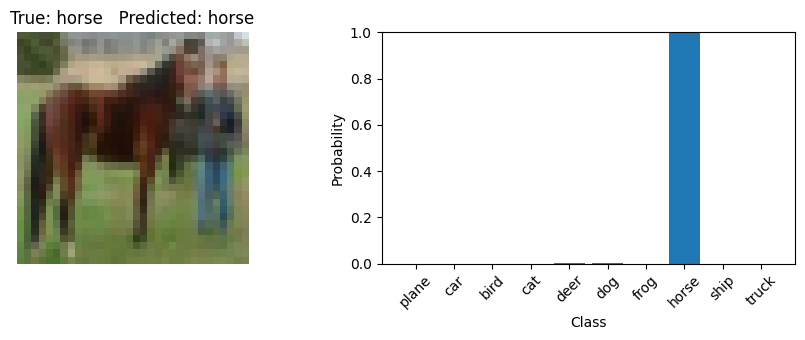

In [26]:
import random
import matplotlib.pyplot as plt

classes = ("plane", "car", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck")

model.eval()

idx = random.randrange(len(test_data))
image, label = test_data[idx]

with torch.no_grad():
    scores = model(image.unsqueeze(0).to(device))
    probs  = torch.softmax(scores, dim=1)[0]
    pred   = probs.argmax().item()

# Undo normalization and reorder (C, H, W) -> (H, W, C) for matplotlib
mean = torch.tensor(Mean).view(3, 1, 1)
std  = torch.tensor(Dev).view(3, 1, 1)
img  = (image * std + mean).clamp(0, 1).permute(1, 2, 0)

fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(9, 3.5))

ax_img.imshow(img)
ax_img.set_title(f"True: {classes[label]}   Predicted: {classes[pred]}")
ax_img.axis("off")

ax_bar.bar(range(10), probs.cpu())
ax_bar.set_xticks(range(10))
ax_bar.set_xticklabels(classes, rotation=45)
ax_bar.set_xlabel("Class")
ax_bar.set_ylabel("Probability")
ax_bar.set_ylim(0, 1)

plt.tight_layout()
plt.show()

## 6)SAVING THE WEIGHT

---

We save the weight for later usage.

In [27]:
torch.save(model.state_dict(), "CIFAR10_fp32.pt")

In [28]:
from google.colab import files
files.download("CIFAR10_fp32.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>